<a href="https://colab.research.google.com/github/pushkar-git438/statistical-foundation-of-data-science/blob/main/Finalpractical/final_practical.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

In [2]:
rng = np.random.default_rng(21)
n = 900

ph = rng.uniform(4.5, 8.5, n)
rain = rng.uniform(400, 2500, n)
temp = rng.uniform(5, 35, n)
nitro = rng.uniform(20, 140, n)

crop = np.where(temp < 15, 'Apple',
                np.where(rain > 1500, 'Rice', 'Wheat'))

flip = rng.random(n) < 0.08
crop[flip] = rng.choice(['Apple', 'Rice', 'Wheat'], flip.sum())

df = pd.DataFrame(dict(
    ph=ph,
    rain=rain,
    temp=temp,
    nitro=nitro,
    crop=crop
))

df.head()

,ph,rain,temp,nitro,crop
0,7.624470,1584.798304,31.351659,52.722683,Rice
1,6.923388,2122.109477,12.910385,59.238288,Apple
2,7.339205,1616.904592,30.353374,107.875804,Rice
3,4.856391,1674.118086,25.075707,40.725620,Rice
4,7.022858,1697.255434,19.666829,123.162411,Apple


In [3]:
print("Dataset Shape:", df.shape)

print("\nCrop Distribution:")
print(df['crop'].value_counts())

print("\nStatistical Summary:")
display(df.describe())

print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape: (900, 5)

Crop Distribution:
crop
Wheat    326
Apple    296
Rice     278
Name: count, dtype: int64

Statistical Summary:


,ph,rain,temp,nitro
count,900.000000,900.000000,900.000000,900.000000
mean,6.496942,1454.589184,20.410975,81.101295
std,1.145281,614.048102,8.725567,35.030271
min,4.500718,401.747073,5.018080,20.046554
25%,5.552524,941.130096,12.612570,50.619531
50%,6.503118,1467.090220,20.176788,82.231661
75%,7.476816,2006.761251,28.355062,112.162339
max,8.495326,2499.601449,34.994850,139.834525



First 5 Rows:


,ph,rain,temp,nitro,crop
0,7.624470,1584.798304,31.351659,52.722683,Rice
1,6.923388,2122.109477,12.910385,59.238288,Apple
2,7.339205,1616.904592,30.353374,107.875804,Rice
3,4.856391,1674.118086,25.075707,40.725620,Rice
4,7.022858,1697.255434,19.666829,123.162411,Apple


In [4]:
X = df[['ph', 'rain', 'temp', 'nitro']]
y = df['crop']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=21
)

model = DecisionTreeClassifier(
    max_depth=3,
    random_state=21
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))
print("Decision Tree Model Trained Successfully")

Training Samples: 720
Testing Samples: 180
Decision Tree Model Trained Successfully


In [5]:
accuracy = accuracy_score(y_test, y_pred)

print("Test Accuracy:", round(accuracy * 100, 2), "%")

labels = ['Apple', 'Rice', 'Wheat']

cm = confusion_matrix(y_test, y_pred, labels=labels)

print("\nConfusion Matrix:")
print(cm)

Test Accuracy: 88.33 %

Confusion Matrix:
[[55  5  4]
 [ 2 43  4]
 [ 1  5 61]]


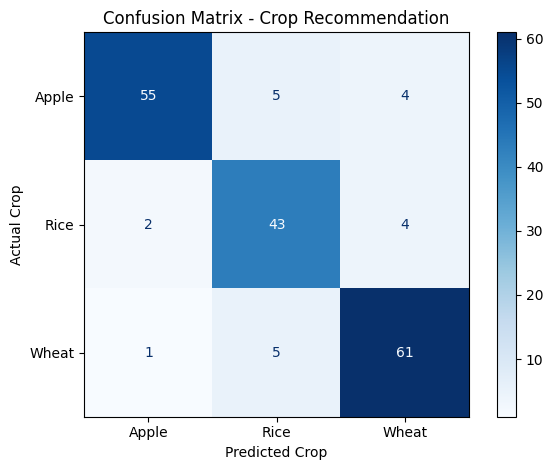

In [6]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(cmap='Blues')

plt.title("Confusion Matrix - Crop Recommendation")
plt.xlabel("Predicted Crop")
plt.ylabel("Actual Crop")
plt.tight_layout()
plt.show()

In [7]:
tree_rules = export_text(
    model,
    feature_names=list(X.columns)
)

print("Decision Tree Rules:")
print(tree_rules)

Decision Tree Rules:
|--- temp <= 15.00
|   |--- nitro <= 83.16
|   |   |--- temp <= 6.05
|   |   |   |--- class: Apple
|   |   |--- temp >  6.05
|   |   |   |--- class: Apple
|   |--- nitro >  83.16
|   |   |--- nitro <= 83.80
|   |   |   |--- class: Wheat
|   |   |--- nitro >  83.80
|   |   |   |--- class: Apple
|--- temp >  15.00
|   |--- rain <= 1501.72
|   |   |--- rain <= 1493.61
|   |   |   |--- class: Wheat
|   |   |--- rain >  1493.61
|   |   |   |--- class: Apple
|   |--- rain >  1501.72
|   |   |--- nitro <= 102.68
|   |   |   |--- class: Rice
|   |   |--- nitro >  102.68
|   |   |   |--- class: Rice



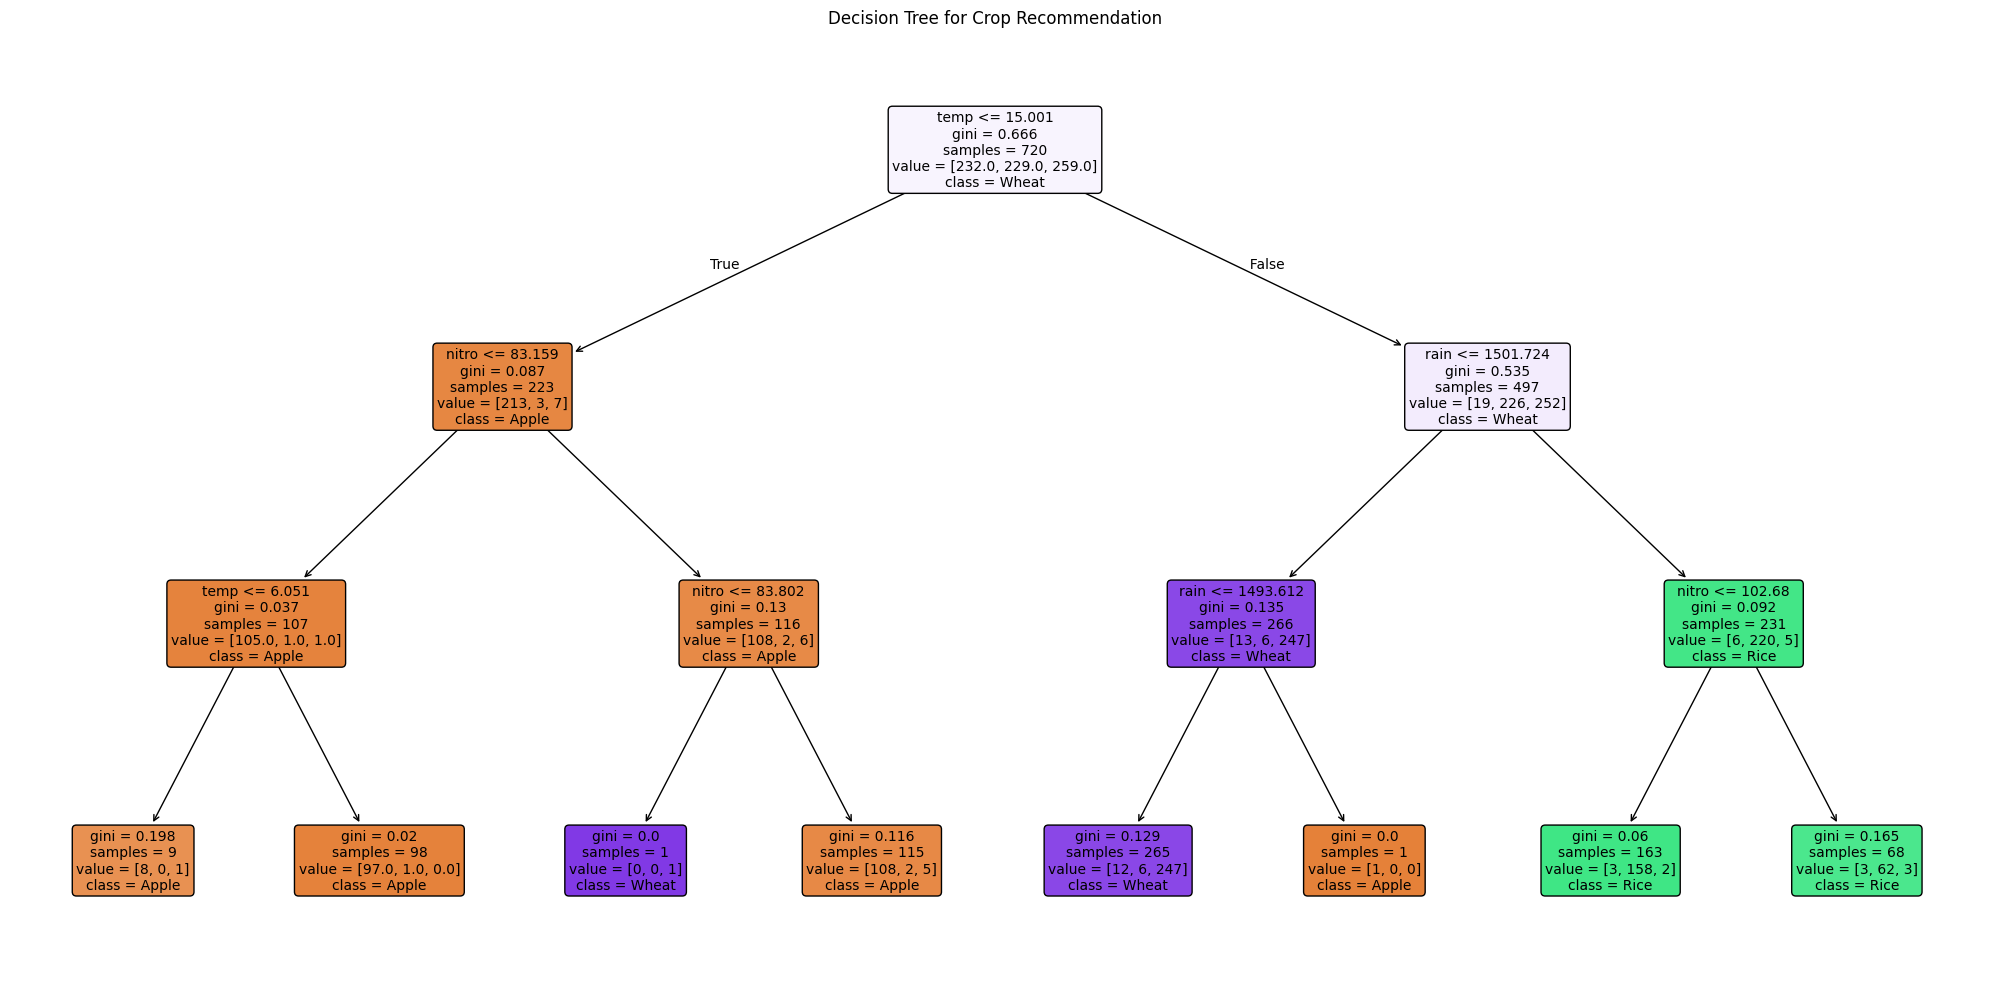

In [8]:
plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=list(X.columns),
    class_names=model.classes_,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree for Crop Recommendation")
plt.tight_layout()
plt.show()

In [9]:
importance = model.feature_importances_

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importance
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("Feature Importances:")
display(feature_importance)

Feature Importances:


,Feature,Importance
1,rain,0.516886
2,temp,0.477549
3,nitro,0.005564
0,ph,0.000000


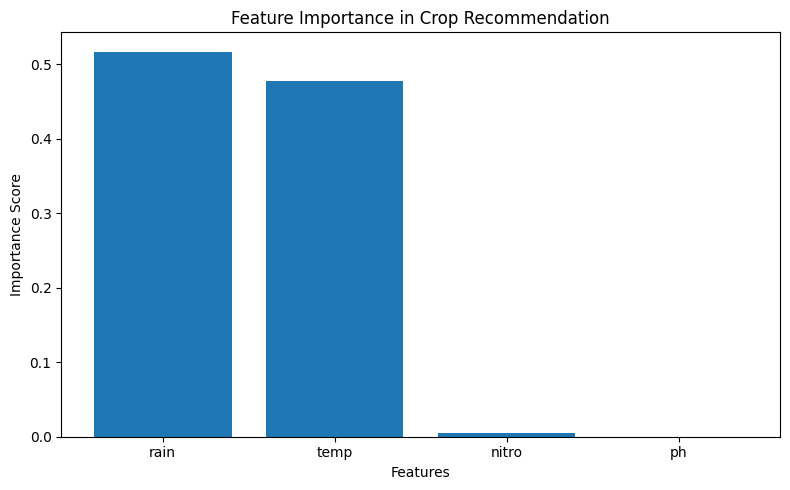

In [10]:
plt.figure(figsize=(8, 5))

plt.bar(
    feature_importance['Feature'],
    feature_importance['Importance']
)

plt.title("Feature Importance in Crop Recommendation")
plt.xlabel("Features")
plt.ylabel("Importance Score")

plt.tight_layout()
plt.show()